# Modelagem Preditiva: Classificação de Atrasos com Seleção de Variáveis
Neste notebook, o objetivo é prever se um pedido vai atrasar (`1`) ou chegar no prazo (`0`). Assim como na regressão, vamos filtrar as 10 variáveis mais determinantes para um pedido atrasar. Isso será fundamental para a próxima etapa, onde extrairemos regras de negócio simples e acionáveis.

In [42]:
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif

# Carregando os dados
df = pd.read_csv('../data/processed/dataset_preprocessed.csv')

# Criando o alvo (y): 1 se o pedido foi além da mediana de tempo (atrasado), 0 caso contrário
mediana_tempo = df['actual_delivery_time_minutes'].median()
df['atrasado'] = (df['actual_delivery_time_minutes'] > mediana_tempo).astype(int)
y = df['atrasado']

# Definindo as variáveis para o teste (Removendo explicitamente os vazamentos de dados)
X_teste_estatistico = df.select_dtypes(include=['number']).drop(columns=[
    'actual_delivery_time_minutes', 
    'late_delivery', 
    'restaurant_preparation_time_minutes',
    'atrasado'
], errors='ignore')

# Calculando a significância usando f_classif (adequado para classificação)
seletor_clf = SelectKBest(score_func=f_classif, k='all')
seletor_clf.fit(X_teste_estatistico, y)

# Criando a tabela de justificativa
df_scores_clf = pd.DataFrame({
    'Variavel': X_teste_estatistico.columns,
    'Nota_Significancia': seletor_clf.scores_
})
df_scores_clf['Importancia_Relativa (%)'] = (df_scores_clf['Nota_Significancia'] / df_scores_clf['Nota_Significancia'].sum()) * 100

print("JUSTIFICATIVA: IMPORTÂNCIA DAS VARIÁVEIS PARA ATRASO")
display(df_scores_clf.sort_values(by='Importancia_Relativa (%)', ascending=False).head(10).round(2))

JUSTIFICATIVA: IMPORTÂNCIA DAS VARIÁVEIS PARA ATRASO


,Variavel,Nota_Significancia,Importancia_Relativa (%)
15,estimated_delivery_time_minutes,45687.43,39.23
12,distance_km,21118.78,18.13
10,order_total,8941.51,7.68
5,subtotal,8197.52,7.04
7,tax_amount,8089.73,6.95
8,service_fee,7079.90,6.08
4,items_count,6862.59,5.89
16,customer_rating,3279.90,2.82
9,delivery_fee,3126.80,2.68
20,traffic_level_Low,1538.02,1.32


## Seleção das Variáveis mais Importantes (Feature Selection)
Utilizamos o teste `f_classif` (ANOVA) para medir a capacidade de cada variável separar os pedidos no prazo dos pedidos atrasados.

In [43]:
# ==============================================================================
# 1. IMPORTAÇÃO E PREPARAÇÃO DOS DADOS
# ==============================================================================
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

# Definindo FIXAMENTE as 6 features mais importantes para classificar atrasos
features_selecionadas_clf = [
    'distance_km', 
    'order_total', 
    'subtotal', 
    'tax_amount', 
    'service_fee', 
    'items_count',
    'order_hour',         
    'traffic_level_Low',
    'traffic_level_Medium'   
]

X_fixo = df[features_selecionadas_clf]

# Divisão em Treino (80%) e Teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X_fixo, y, test_size=0.2, random_state=42)

print(f"Treinando o modelo de Classificação com {X_train.shape[1]} variáveis fixas.")

Treinando o modelo de Classificação com 9 variáveis fixas.


## Treinamento e Gráfico de Desempenho
Vamos treinar a Regressão Logística apenas com o "suco" da nossa base de dados (as 10 melhores features) e visualizar os acertos e erros através de um gráfico de barras intuitivo.

In [44]:
# ==============================================================================
# 2. TREINAMENTO DO MODELO
# ==============================================================================
modelo_class = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

# Treinando o modelo
modelo_class.fit(X_train, y_train)

# Fazendo previsões
y_pred = modelo_class.predict(X_test)

# Calculando Acurácia
acuracia = accuracy_score(y_test, y_pred)
print(f"Acurácia do Modelo: {acuracia * 100:.2f}%\n")

Acurácia do Modelo: 87.40%



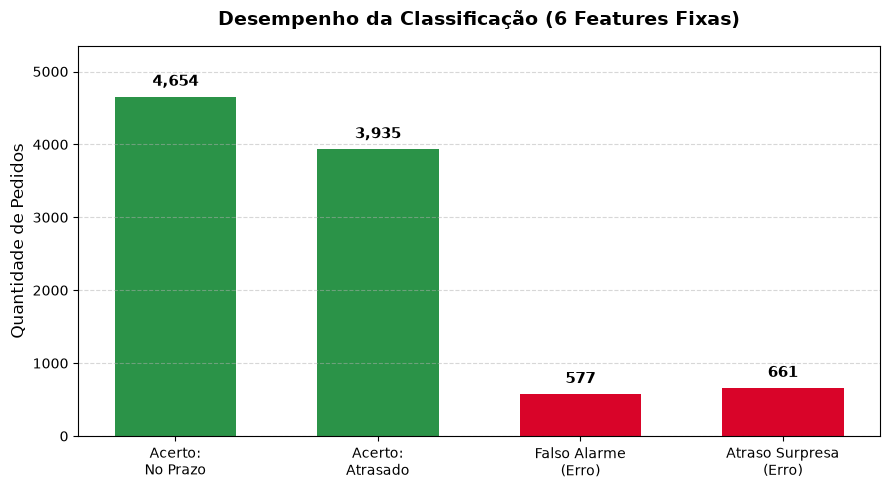

In [45]:
# ==============================================================================
# 3. GRÁFICO DE DESEMPENHO (ACERTOS VS ERROS)
# ==============================================================================
# Garantindo que a pasta de destino exista
os.makedirs('../reports/figures', exist_ok=True)

cm = confusion_matrix(y_test, y_pred)
acerto_no_prazo = cm[0, 0]
falso_alarme = cm[0, 1]
atraso_surpresa = cm[1, 0]
acerto_atrasado = cm[1, 1]

categorias = ['Acerto:\nNo Prazo', 'Acerto:\nAtrasado', 'Falso Alarme\n(Erro)', 'Atraso Surpresa\n(Erro)']
valores = [acerto_no_prazo, acerto_atrasado, falso_alarme, atraso_surpresa]
cores = ['#2b9348', '#2b9348', '#d90429', '#d90429']

plt.figure(figsize=(9, 5))
bars = plt.bar(categorias, valores, color=cores, width=0.6)

# Adicionando os valores em cima das barras
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f'{yval:,}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title('Desempenho da Classificação (6 Features Fixas)', fontsize=14, pad=15, fontweight='bold')
plt.ylabel('Quantidade de Pedidos', fontsize=12)
plt.ylim(0, max(valores) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

# SALVANDO A IMAGEM PARA O RELATÓRIO LATEX
plt.savefig('../reports/figures/classification_bar_chart.png', dpi=300, bbox_inches='tight')